# Task 5: Decision Trees and Random Forests
### This notebook covers
- Decision Tree Classifier
- Decision Tree visualization
- Overfitting analysis using tree depth
- Random Forest Classifier
- Accuracy comparison
- Feature importance
- Cross-validation


## 1. Import Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from IPython.display import display

# Create output directory
os.makedirs("outputs", exist_ok=True)

# Display settings
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Load the Dataset

Place your dataset at:

`dataset/heart.csv`

The expected target column is `target`.


In [2]:
DATA_PATH = "D:\\Day-5-task-Elevate-Lab---Nishita-kanojiya\\Dataset\\heart.csv"

if not os.path.exists(DATA_PATH):
    DATA_PATH = "dataset/heart.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

display(df.head())


Dataset loaded successfully.
Shape: (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


## 3. Understand the Dataset

In [3]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate Rows:", df.duplicated().sum())


Dataset Shape: (1025, 14)

Column Names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Data Types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object

Missing Values:


,Missing Values
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0



Duplicate Rows: 723


## 4. Basic Statistical Analysis

In [4]:
display(df.describe().T)


,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.695610,0.460373,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.942439,1.029641,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.000000,51.592510,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.149268,0.356527,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.529756,0.527878,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.336585,0.472772,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2


## 5. Check Target Distribution

Target Distribution:


target
1    526
0    499
Name: count, dtype: int64

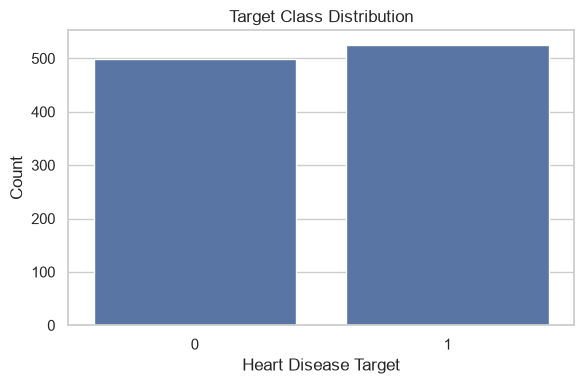

In [5]:
if "target" not in df.columns:
    raise ValueError("The dataset must contain a 'target' column.")

print("Target Distribution:")
display(df["target"].value_counts())

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="target")
plt.title("Target Class Distribution")
plt.xlabel("Heart Disease Target")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("outputs/target_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


## 6. Data Preprocessing

For this classification task:
- `target` is the dependent variable.
- All remaining columns are used as features.
- Missing numerical values are filled with the median.
- Missing categorical values are filled with the mode.
- Categorical columns are converted using one-hot encoding.


In [6]:
# Separate features and target
X = df.drop(columns=["target"]).copy()
y = df["target"].copy()

# Identify numeric and categorical columns
numeric_columns = X.select_dtypes(include=np.number).columns.tolist()
categorical_columns = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical columns:", numeric_columns)
print("Categorical columns:", categorical_columns)

# Handle missing values
if numeric_columns:
    X[numeric_columns] = X[numeric_columns].fillna(X[numeric_columns].median())

if categorical_columns:
    for col in categorical_columns:
        X[col] = X[col].fillna(X[col].mode()[0])

# Encode categorical features if present
X = pd.get_dummies(X, columns=categorical_columns, drop_first=True, dtype=int)

print("\nProcessed feature shape:", X.shape)
display(X.head())


Numerical columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
Categorical columns: []

Processed feature shape: (1025, 13)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2


## 7. Train-Test Split

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data :", X_test.shape)


Training data: (820, 13)
Testing data : (205, 13)


## 8. Train a Decision Tree Classifier

In [8]:
dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", round(dt_accuracy, 4))


Decision Tree Accuracy: 0.9854


## 9. Decision Tree Classification Report

In [9]:
print("Decision Tree Classification Report:")
print(classification_report(y_test, y_pred_dt))


Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99       100
           1       1.00      0.97      0.99       105

    accuracy                           0.99       205
   macro avg       0.99      0.99      0.99       205
weighted avg       0.99      0.99      0.99       205



## 10. Decision Tree Confusion Matrix

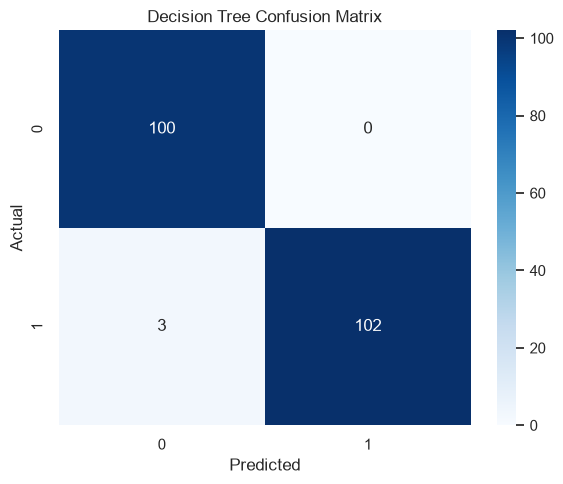

In [10]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=np.unique(y),
    yticklabels=np.unique(y)
)
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig("outputs/decision_tree_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


## 11. Visualize the Decision Tree

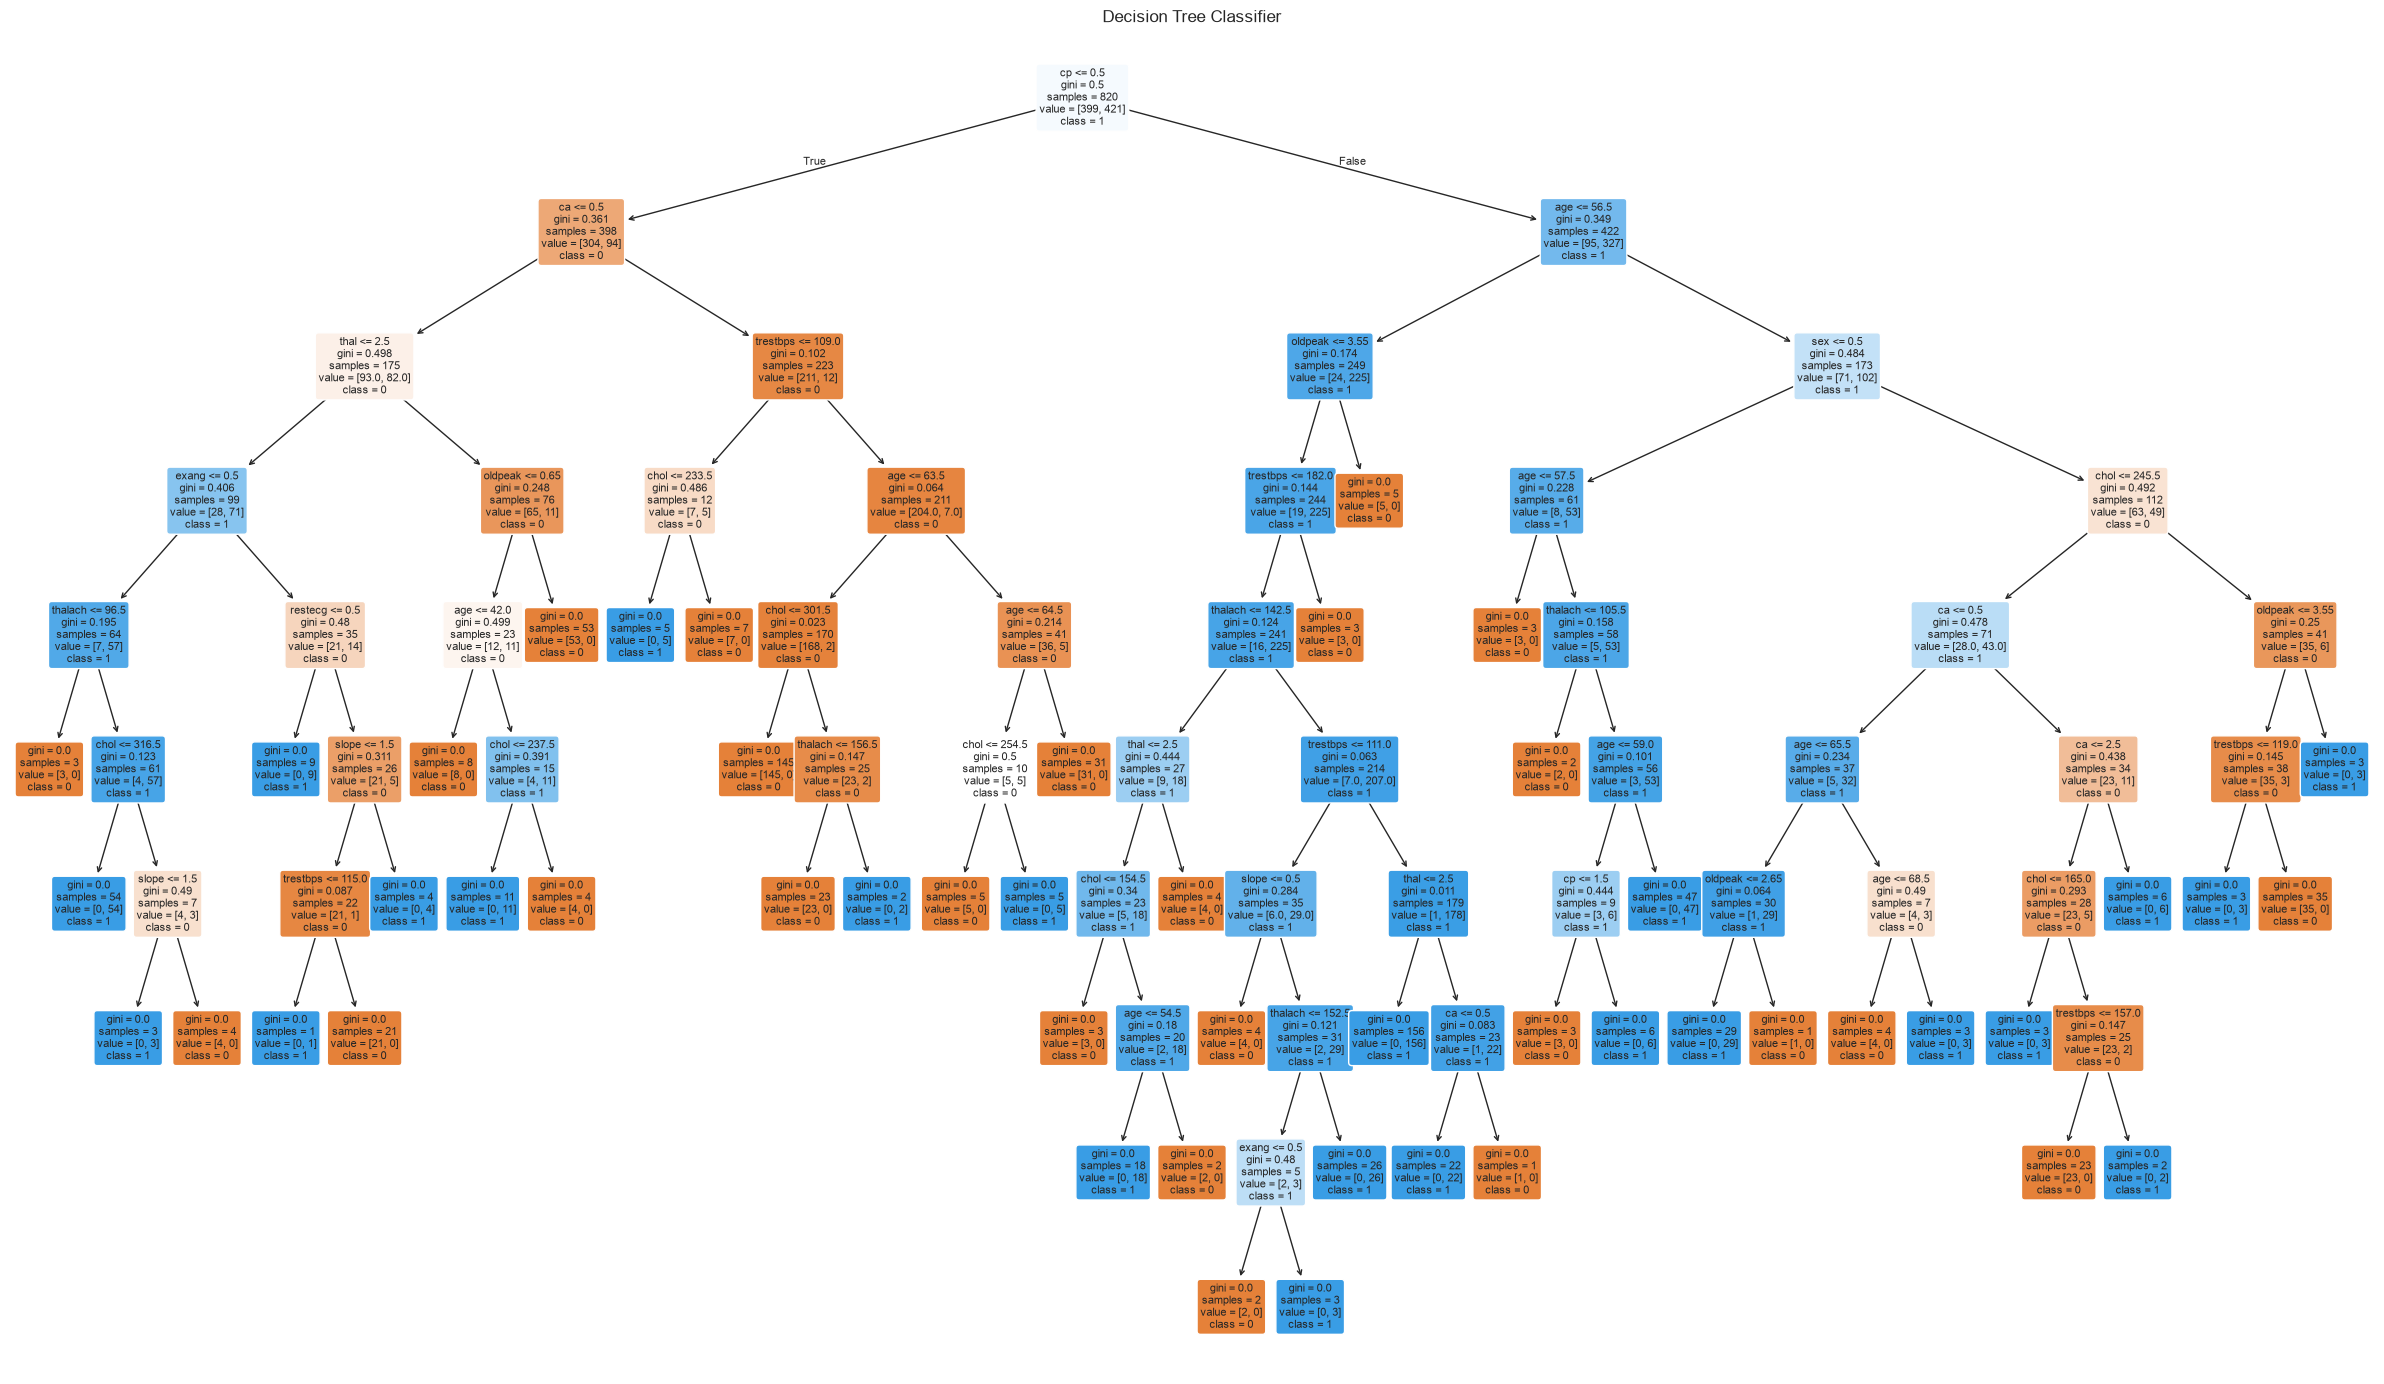

In [11]:
plt.figure(figsize=(24, 14))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=[str(c) for c in sorted(y.unique())],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Classifier")
plt.tight_layout()
plt.savefig("outputs/decision_tree.png", dpi=300, bbox_inches="tight")
plt.show()


## 12. Analyze Overfitting Using Tree Depth

A very deep decision tree can memorize the training data and perform poorly on unseen data.

We compare training and testing accuracy for different values of `max_depth`.


In [12]:
depths = range(1, 16)

train_scores = []
test_scores = []

for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_scores.append(model.score(X_train, y_train))
    test_scores.append(model.score(X_test, y_test))

depth_results = pd.DataFrame({
    "max_depth": list(depths),
    "training_accuracy": train_scores,
    "testing_accuracy": test_scores
})

display(depth_results)


,max_depth,training_accuracy,testing_accuracy
0,1,0.769512,0.721951
1,2,0.769512,0.721951
2,3,0.845122,0.853659
3,4,0.885366,0.839024
4,5,0.929268,0.873171
5,6,0.965854,0.921951
6,7,0.991463,0.951220
7,8,0.997561,0.975610
8,9,1.000000,0.985366
9,10,1.000000,0.985366


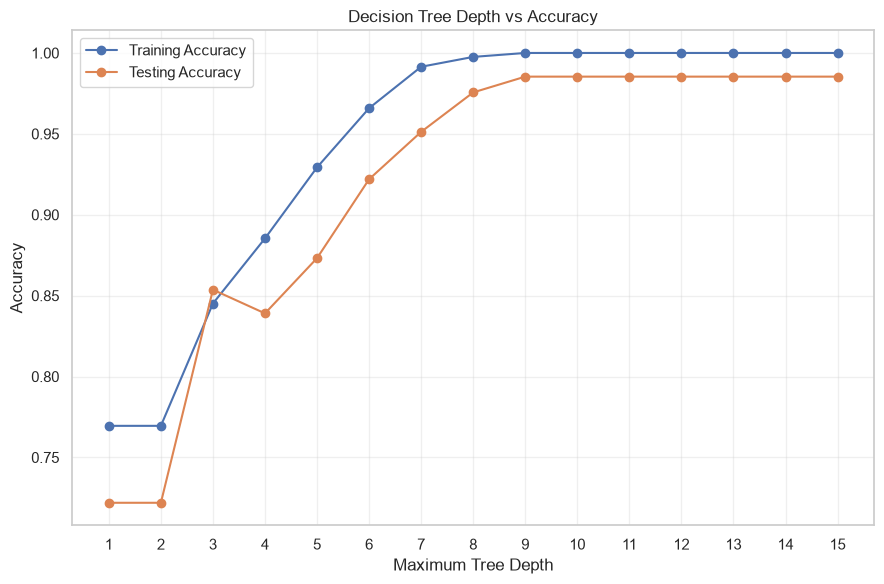

In [13]:
plt.figure(figsize=(9, 6))

plt.plot(
    depth_results["max_depth"],
    depth_results["training_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    depth_results["max_depth"],
    depth_results["testing_accuracy"],
    marker="o",
    label="Testing Accuracy"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree Depth vs Accuracy")
plt.xticks(list(depths))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("outputs/depth_vs_accuracy.png", dpi=300, bbox_inches="tight")
plt.show()


### Overfitting Observation

If training accuracy continues increasing while testing accuracy stops improving or decreases, the tree is beginning to overfit.

A smaller `max_depth` can reduce model complexity and improve generalization.


## 13. Train a Controlled Decision Tree

In [15]:
# Choose the depth that gives the best testing accuracy
best_depth = int(
    depth_results.loc[
        depth_results["testing_accuracy"].idxmax(),
        "max_depth"
    ]
)

print("Best depth based on test accuracy:", best_depth)

dt_tuned = DecisionTreeClassifier(
    max_depth=best_depth,
    random_state=42
)

dt_tuned.fit(X_train, y_train)

y_pred_dt_tuned = dt_tuned.predict(X_test)

dt_tuned_accuracy = accuracy_score(y_test, y_pred_dt_tuned)

print("Tuned Decision Tree Accuracy:", round(dt_tuned_accuracy, 4))


Best depth based on test accuracy: 9
Tuned Decision Tree Accuracy: 0.9854


## 14. Train a Random Forest Classifier

In [17]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", round(rf_accuracy, 4))


Random Forest Accuracy: 1.0


## 15. Random Forest Classification Report

In [18]:
print("Random Forest Classification Report:")
print(classification_report(y_test, y_pred_rf))


Random Forest Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       100
           1       1.00      1.00      1.00       105

    accuracy                           1.00       205
   macro avg       1.00      1.00      1.00       205
weighted avg       1.00      1.00      1.00       205



## 16. Random Forest Confusion Matrix

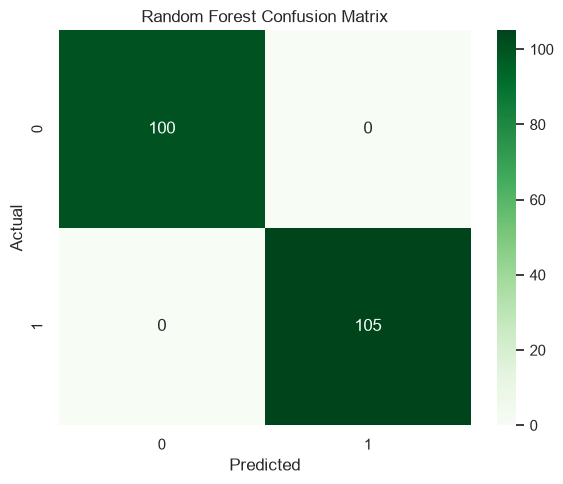

In [19]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=np.unique(y),
    yticklabels=np.unique(y)
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()

plt.savefig("outputs/random_forest_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


## 17. Compare Decision Tree and Random Forest

In [20]:
comparison = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Tuned Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        dt_accuracy,
        dt_tuned_accuracy,
        rf_accuracy
    ]
})

display(comparison)


,Model,Accuracy
0,Decision Tree,0.985366
1,Tuned Decision Tree,0.985366
2,Random Forest,1.000000


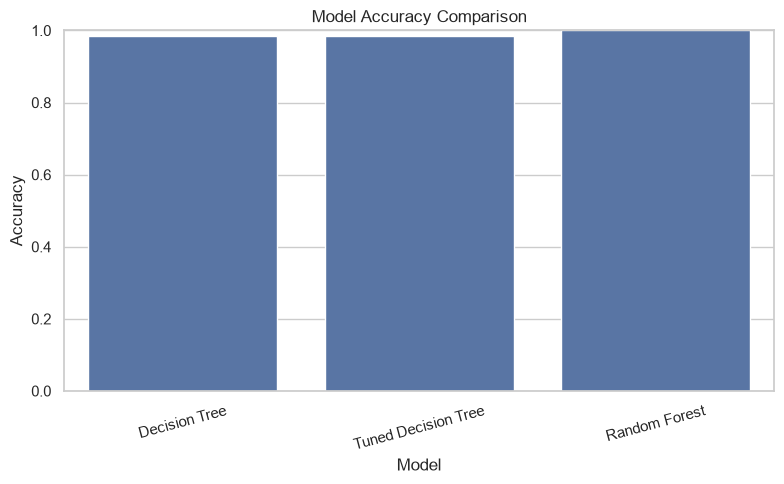

In [21]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Accuracy"
)

plt.ylim(0, 1)
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig("outputs/model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


## 18. Interpret Feature Importance

Random Forest provides an importance score for every feature.

A higher value means the feature contributed more to the model's decision-making process.


In [22]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)


,Feature,Importance
2,cp,0.142094
7,thalach,0.117349
11,ca,0.114844
9,oldpeak,0.112634
12,thal,0.095930
0,age,0.091285
4,chol,0.077771
8,exang,0.073707
3,trestbps,0.067765
10,slope,0.048711


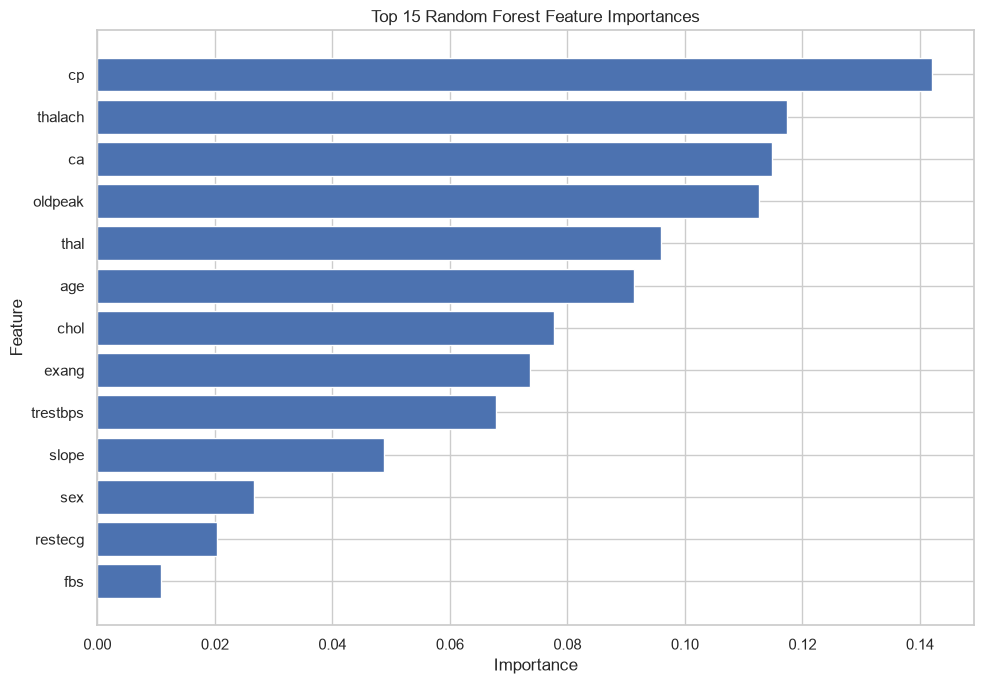

In [23]:
plt.figure(figsize=(10, 7))

top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Random Forest Feature Importances")
plt.tight_layout()

plt.savefig("outputs/feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()


## 19. Cross-Validation

We use Stratified K-Fold cross-validation so that each fold maintains a similar class distribution.


In [28]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

dt_cv_scores = cross_val_score(
    dt_tuned,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

rf_cv_scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

cv_results = pd.DataFrame({
    "Fold": range(1, 6),
    "Decision Tree": dt_cv_scores,
    "Random Forest": rf_cv_scores
})

display(cv_results)

print("Decision Tree Mean CV Accuracy:",
      round(dt_cv_scores.mean(), 4))

print("Random Forest Mean CV Accuracy:",
      round(rf_cv_scores.mean(), 4))



,Fold,Decision Tree,Random Forest
0,1,1.000000,1.000000
1,2,1.000000,1.000000
2,3,1.000000,1.000000
3,4,0.985366,0.980488
4,5,1.000000,1.000000


Decision Tree Mean CV Accuracy: 0.9971
Random Forest Mean CV Accuracy: 0.9961


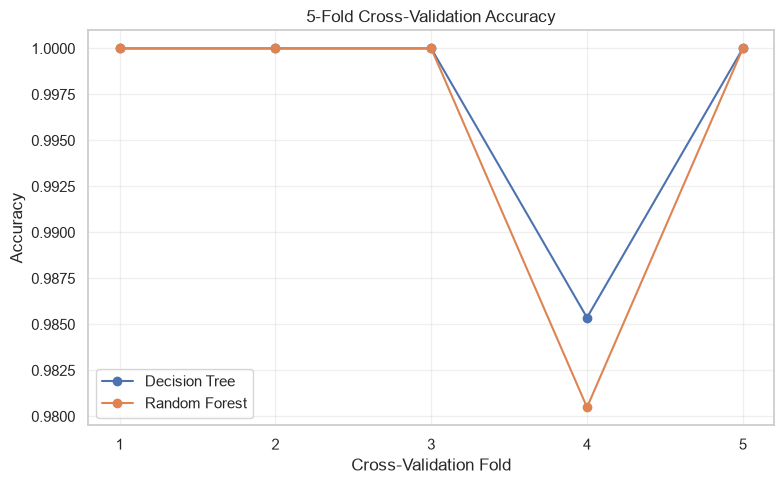

In [29]:
plt.figure(figsize=(8, 5))

x = np.arange(1, 6)

plt.plot(
    x,
    dt_cv_scores,
    marker="o",
    label="Decision Tree"
)

plt.plot(
    x,
    rf_cv_scores,
    marker="o",
    label="Random Forest"
)

plt.xlabel("Cross-Validation Fold")
plt.ylabel("Accuracy")
plt.title("5-Fold Cross-Validation Accuracy")
plt.xticks(x)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("outputs/cross_validation.png", dpi=300, bbox_inches="tight")
plt.show()


## 20. Final Model Evaluation

In [30]:
final_results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Tuned Decision Tree",
        "Random Forest"
    ],
    "Test Accuracy": [
        dt_accuracy,
        dt_tuned_accuracy,
        rf_accuracy
    ],
    "5-Fold CV Mean Accuracy": [
        dt_cv_scores.mean(),
        cross_val_score(dt_tuned, X, y, cv=cv, scoring="accuracy").mean(),
        rf_cv_scores.mean()
    ]
})

display(final_results.round(4))


,Model,Test Accuracy,5-Fold CV Mean Accuracy
0,Decision Tree,0.9854,0.9971
1,Tuned Decision Tree,0.9854,0.9971
2,Random Forest,1.0000,0.9961


## 21. Conclusion

### Key observations
- A Decision Tree is easy to interpret and visualize.
- Increasing tree depth can increase training accuracy but may cause overfitting.
- Limiting `max_depth` helps control tree complexity.
- Random Forest combines multiple decision trees and generally provides more robust predictions than a single tree.
- Feature importance helps identify which features contribute most to the Random Forest predictions.
- Cross-validation gives a more reliable estimate of model performance than relying on a single train-test split.

### Task 5 : 
The notebook covers:
- Decision Tree training
- Decision Tree visualization
- Overfitting/depth analysis
- Random Forest training
- Accuracy comparison
- Feature importance
- Cross-validation
